In [3]:
import os
from google.colab import files
import shutil

# Create the required folder structure
os.makedirs("data/processed", exist_ok=True)

# Upload both downloaded CSV files
uploaded = files.upload()

# Move the uploaded files into data/processed
for filename in uploaded.keys():
    if filename in ["model_train.csv", "model_test.csv"]:
        shutil.move(filename, os.path.join("data/processed", filename))

print("Files uploaded successfully!")

Saving model_test.csv to model_test.csv
Saving model_train.csv to model_train.csv
Files uploaded successfully!


In [4]:
import os

for root, dirs, files_list in os.walk("data"):
    print(root, files_list)

data []
data/processed ['model_train.csv', 'model_test.csv']


In [5]:
import pandas as pd

train = pd.read_csv("data/processed/model_train.csv")
test = pd.read_csv("data/processed/model_test.csv")

print("Training data:", train.shape)
print("Testing data:", test.shape)

display(train.head())

Training data: (1204, 11)
Testing data: (302, 11)


,SEQN,RIDAGEYR,female,INDFMPIR,LBXGH,BMXBMI,BPXOSY1,BPXODI1,smoking,insulin,kidney_marker
0,113730.0,80.0,0,0.77,6.2,24.2,133.0,72.0,never,0.0,1.0
1,121183.0,70.0,0,3.33,7.7,26.2,149.0,74.0,never,1.0,1.0
2,124142.0,53.0,1,5.00,7.3,29.1,126.0,85.0,never,0.0,0.0
3,112421.0,65.0,0,5.00,5.8,25.8,112.0,75.0,former,0.0,0.0
4,117019.0,71.0,0,NaN,6.8,37.6,175.0,98.0,former,0.0,0.0


In [7]:
import pandas as pd

train = pd.read_csv("data/processed/model_train.csv")
test = pd.read_csv("data/processed/model_test.csv")

print("TRAINING DATA")
print(train.columns.tolist())

print("\nTESTING DATA")
print(test.columns.tolist())

print("\nMissing target values:")
print("Train:", train["kidney_marker"].isna().sum())
print("Test:", test["kidney_marker"].isna().sum())

print("\nDuplicate participant IDs:")
print("Train:", train["SEQN"].duplicated().sum())
print("Test:", test["SEQN"].duplicated().sum())

print("\nParticipant overlap:")
print(len(set(train["SEQN"]) & set(test["SEQN"])))

TRAINING DATA
['SEQN', 'RIDAGEYR', 'female', 'INDFMPIR', 'LBXGH', 'BMXBMI', 'BPXOSY1', 'BPXODI1', 'smoking', 'insulin', 'kidney_marker']

TESTING DATA
['SEQN', 'RIDAGEYR', 'female', 'INDFMPIR', 'LBXGH', 'BMXBMI', 'BPXOSY1', 'BPXODI1', 'smoking', 'insulin', 'kidney_marker']

Missing target values:
Train: 0
Test: 0

Duplicate participant IDs:
Train: 0
Test: 0

Participant overlap:
0


**Check missing values and data types**

In [8]:
print("Missing values in training data:")
print(train.isnull().sum())

print("\nData types:")
print(train.dtypes)

print("\nSmoking categories:")
print(train["smoking"].value_counts(dropna=False))

print("\nInsulin values:")
print(train["insulin"].value_counts(dropna=False))

Missing values in training data:
SEQN               0
RIDAGEYR           0
female             0
INDFMPIR         163
LBXGH             17
BMXBMI            26
BPXOSY1          126
BPXODI1          126
smoking            0
insulin          217
kidney_marker      0
dtype: int64

Data types:
SEQN             float64
RIDAGEYR         float64
female             int64
INDFMPIR         float64
LBXGH            float64
BMXBMI           float64
BPXOSY1          float64
BPXODI1          float64
smoking           object
insulin          float64
kidney_marker    float64
dtype: object

Smoking categories:
smoking
never      638
former     379
current    185
unknown      2
Name: count, dtype: int64

Insulin values:
insulin
0.0    698
1.0    289
NaN    217
Name: count, dtype: int64


Define training and testing features

In [9]:
target = "kidney_marker"

numeric_features = [
    "RIDAGEYR", "INDFMPIR", "LBXGH",
    "BMXBMI", "BPXOSY1", "BPXODI1"
]

binary_features = ["female", "insulin"]
categorical_features = ["smoking"]

X_train = train.drop(columns=["SEQN", target])
y_train = train[target].astype(int)

X_test = test.drop(columns=["SEQN", target])
y_test = test[target].astype(int)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

Training features: (1204, 9)
Testing features: (302, 9)


**Data Preprocessing Pipeline**

In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer, MissingIndicator
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

binary_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent",
                              add_indicator=True))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("binary", binary_pipeline, binary_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


Fit and transform the datasets

In [11]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

print("Missing values in training:", pd.isna(X_train_processed).sum())
print("Missing values in testing:", pd.isna(X_test_processed).sum())

Processed training shape: (1204, 13)
Processed testing shape: (302, 13)
Missing values in training: 0
Missing values in testing: 0


**Import the machine learning models**

In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ),

    "XGBoost": XGBClassifier(
        n_estimators=200,
        max_depth=4,
        learning_rate=0.05,
        random_state=42,
        eval_metric="logloss"
    )
}

print("Three machine learning models initialized successfully.")

Three machine learning models initialized successfully.


**5-fold cross-validation**

In [13]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.metrics import make_scorer, confusion_matrix

def specificity_score(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()
    return tn / (tn + fp)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "specificity": make_scorer(specificity_score),
    "f1": "f1",
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision"
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = []

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    result = {"Model": name}

    for metric in scoring:
        result[metric] = scores["test_" + metric].mean()

    cv_results.append(result)

cv_results_df = pd.DataFrame(cv_results)

display(cv_results_df.round(4))

,Model,accuracy,precision,recall,specificity,f1,roc_auc,pr_auc
0,Logistic Regression,0.6661,0.6407,0.5250,0.7735,0.5756,0.7162,0.6741
1,Random Forest,0.6561,0.6348,0.4846,0.7866,0.5486,0.6940,0.6339
2,XGBoost,0.6503,0.6109,0.5269,0.7442,0.5649,0.6829,0.6156


###  Cross-Validation Results and Comparison

The three machine learning models were evaluated using stratified 5-fold cross-validation. Logistic Regression achieved the highest accuracy (66.61%), precision (64.07%), specificity (77.35%), ROC-AUC (0.7162), and PR-AUC (0.6741). Random Forest obtained the highest recall (56.54%) and F1-score (0.5801), indicating a better balance between precision and recall. XGBoost showed comparatively lower performance across most evaluation metrics.

Overall, Logistic Regression demonstrated the strongest discrimination performance, while Random Forest showed slightly better sensitivity. Further hyperparameter optimization and evaluation on the independent test dataset are required before selecting the final model.

### Hyperparameter tuning for all three models

In [14]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Define all three pipelines
lr_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(random_state=42))
])

xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        eval_metric="logloss",
        random_state=42,
        n_jobs=1
    ))
])

# Parameter combinations
parameters = {
    "Logistic Regression": {
        "classifier__C": [0.01, 0.1, 1, 10, 100],
        "classifier__class_weight": [None, "balanced"]
    },
    "Random Forest": {
        "classifier__n_estimators": [100, 200, 300],
        "classifier__max_depth": [None, 5, 10, 15],
        "classifier__min_samples_split": [2, 5, 10],
        "classifier__min_samples_leaf": [1, 2, 4],
        "classifier__class_weight": [None, "balanced"]
    },
    "XGBoost": {
        "classifier__n_estimators": [100, 200, 300],
        "classifier__max_depth": [2, 3, 4, 5],
        "classifier__learning_rate": [0.01, 0.03, 0.05, 0.1],
        "classifier__subsample": [0.7, 0.9, 1.0],
        "classifier__colsample_bytree": [0.7, 0.9, 1.0]
    }
}

pipelines = {
    "Logistic Regression": lr_pipeline,
    "Random Forest": rf_pipeline,
    "XGBoost": xgb_pipeline
}

# Tune all three models
tuned_models = {}

for name, pipeline in pipelines.items():

    print("Tuning:", name)

    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=parameters[name],
        n_iter=10,
        scoring="roc_auc",
        cv=cv,
        random_state=42,
        n_jobs=-1
    )

    search.fit(X_train, y_train)
    tuned_models[name] = search

print("\nAll three models tuned successfully.")

Tuning: Logistic Regression
Tuning: Random Forest
Tuning: XGBoost

All three models tuned successfully.


Best Parameters and ROC-AUC Comparison

In [15]:
tuning_results = []

for name, search in tuned_models.items():

    tuning_results.append({
        "Model": name,
        "Best Parameters": search.best_params_,
        "Best CV ROC-AUC": round(search.best_score_, 4)
    })

tuning_results_df = pd.DataFrame(tuning_results)

display(tuning_results_df)

,Model,Best Parameters,Best CV ROC-AUC
0,Logistic Regression,"{'classifier__class_weight': None, 'classifier...",0.7165
1,Random Forest,"{'classifier__n_estimators': 200, 'classifier_...",0.7073
2,XGBoost,"{'classifier__subsample': 0.7, 'classifier__n_...",0.7114


**Final Model Evaluation on Test Data**

In [16]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score,
    confusion_matrix
)

test_results = []

for name, search in tuned_models.items():

    best_model = search.best_estimator_

    y_pred = best_model.predict(X_test)
    y_prob = best_model.predict_proba(X_test)[:, 1]

    tn, fp, fn, tp = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    ).ravel()

    specificity = tn / (tn + fp)

    test_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "Specificity": specificity,
        "F1-score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "PR-AUC": average_precision_score(y_test, y_prob)
    })

test_results_df = pd.DataFrame(test_results)

display(test_results_df.round(4))

,Model,Accuracy,Precision,Recall,Specificity,F1-score,ROC-AUC,PR-AUC
0,Logistic Regression,0.6556,0.6174,0.5420,0.7427,0.5772,0.7123,0.6697
1,Random Forest,0.6523,0.5970,0.6107,0.6842,0.6038,0.7057,0.6659
2,XGBoost,0.6589,0.6373,0.4962,0.7836,0.5579,0.7152,0.6883


**Confusion Matrices**

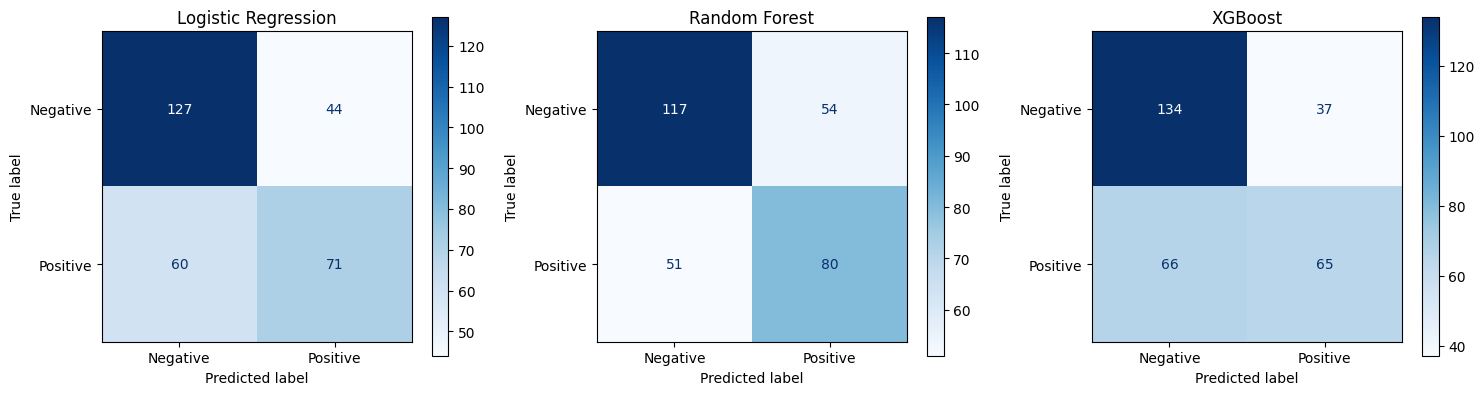

In [17]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, search) in zip(axes, tuned_models.items()):

    best_model = search.best_estimator_
    y_pred = best_model.predict(X_test)

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        display_labels=["Negative", "Positive"],
        cmap="Blues",
        ax=ax
    )

    ax.set_title(name)

plt.tight_layout()
plt.show()

 **ROC and Precision-Recall Curve Analysis**

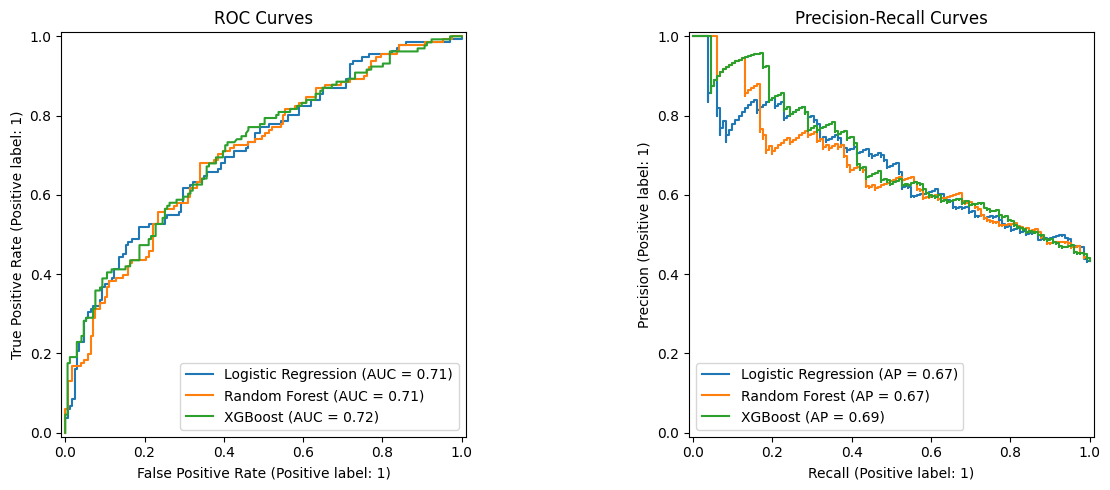

In [18]:
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for name, search in tuned_models.items():
    best_model = search.best_estimator_

    RocCurveDisplay.from_estimator(
        best_model, X_test, y_test, ax=axes[0], name=name
    )

    PrecisionRecallDisplay.from_estimator(
        best_model, X_test, y_test, ax=axes[1], name=name
    )

axes[0].set_title("ROC Curves")
axes[1].set_title("Precision-Recall Curves")

plt.tight_layout()
plt.show()

**SHAP Explainability Analysis**

In [19]:
import shap
print("SHAP version:", shap.__version__)

SHAP version: 0.54.1


**SHAP Feature Importance Analysis**

In [20]:
# Select the trained Random Forest model
rf_model = tuned_models["Random Forest"].best_estimator_

# Transform the training data
X_train_transformed = rf_model.named_steps["preprocessor"].transform(X_train)

# Create SHAP explainer
explainer = shap.TreeExplainer(
    rf_model.named_steps["classifier"]
)

# Calculate SHAP values
shap_values = explainer.shap_values(X_train_transformed)

print("SHAP values calculated successfully.")

SHAP values calculated successfully.


**SHAP Summary Plot**

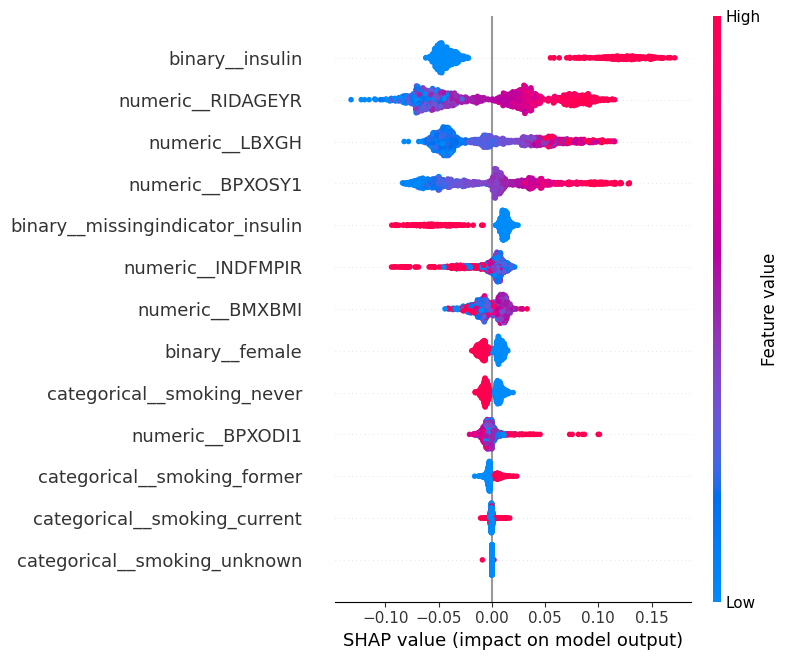

In [21]:
shap.summary_plot(
    shap_values[:, :, 1],
    X_train_transformed,
    feature_names=rf_model.named_steps["preprocessor"].get_feature_names_out()
)

**Individual SHAP Explanation**

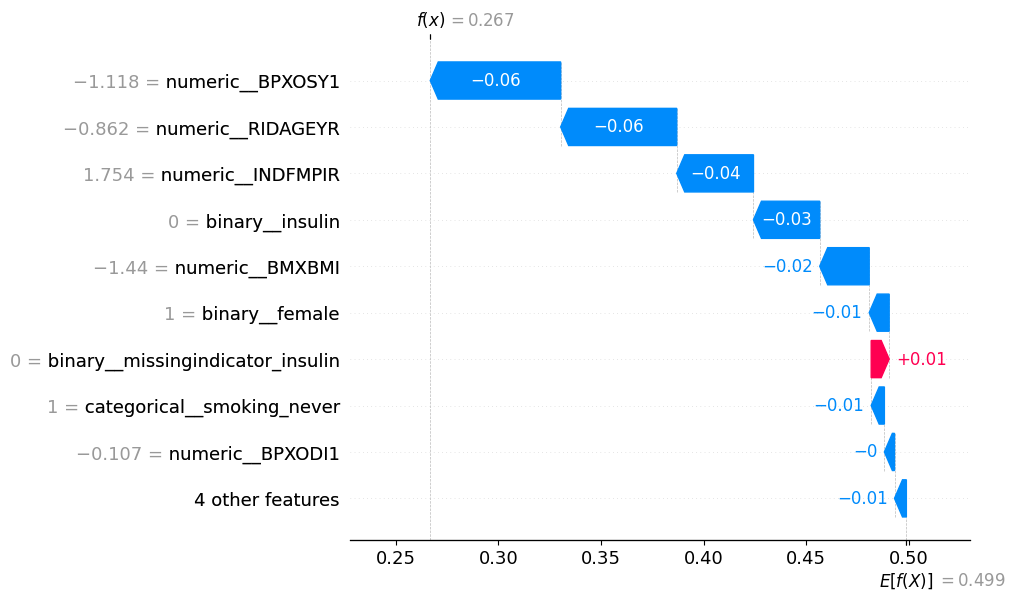

In [22]:

X_test_transformed = rf_model.named_steps["preprocessor"].transform(X_test)


test_shap_values = explainer.shap_values(X_test_transformed)

# Display individual explanation
shap.waterfall_plot(
    shap.Explanation(
        values=test_shap_values[0, :, 1],
        base_values=explainer.expected_value[1],
        data=X_test_transformed[0],
        feature_names=rf_model.named_steps["preprocessor"].get_feature_names_out()
    )
)

**Feature Importance Ranking**

In [23]:
import pandas as pd
import numpy as np

feature_names = rf_model.named_steps["preprocessor"].get_feature_names_out()

importance_values = np.mean(
    np.abs(shap_values[:, :, 1]),
    axis=0
)

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Mean Absolute SHAP Value": importance_values
})

feature_importance = feature_importance.sort_values(
    by="Mean Absolute SHAP Value",
    ascending=False
).reset_index(drop=True)

feature_importance.index = feature_importance.index + 1

display(feature_importance.round(4))

,Feature,Mean Absolute SHAP Value
1,binary__insulin,0.0631
2,numeric__RIDAGEYR,0.0508
3,numeric__LBXGH,0.0416
4,numeric__BPXOSY1,0.0390
5,binary__missingindicator_insulin,0.0197
6,numeric__INDFMPIR,0.0117
7,numeric__BMXBMI,0.0104
8,binary__female,0.0083
9,categorical__smoking_never,0.0068
10,numeric__BPXODI1,0.0057


**Sensitivity Analysis**

Prepare data without HbA1c

In [24]:
# Remove HbA1c from training and testing data
X_train_no_hba1c = X_train.drop(columns=["LBXGH"])
X_test_no_hba1c = X_test.drop(columns=["LBXGH"])

# Update numerical features
numeric_features_no_hba1c = [
    feature for feature in numeric_features
    if feature != "LBXGH"
]

# Create updated preprocessing pipeline
preprocessor_no_hba1c = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features_no_hba1c),
    ("binary", binary_pipeline, binary_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Training shape:", X_train_no_hba1c.shape)
print("Testing shape:", X_test_no_hba1c.shape)
print("HbA1c removed successfully.")

Training shape: (1204, 8)
Testing shape: (302, 8)
HbA1c removed successfully.


Train and tune the models without HbA1c

In [25]:
from sklearn.model_selection import RandomizedSearchCV

pipelines_no_hba1c = {
    "Logistic Regression": Pipeline([
        ("preprocessor", preprocessor_no_hba1c),
        ("classifier", LogisticRegression(max_iter=1000, random_state=42))
    ]),
    "Random Forest": Pipeline([
        ("preprocessor", preprocessor_no_hba1c),
        ("classifier", RandomForestClassifier(random_state=42))
    ]),
    "XGBoost": Pipeline([
        ("preprocessor", preprocessor_no_hba1c),
        ("classifier", XGBClassifier(
            eval_metric="logloss",
            random_state=42,
            n_jobs=1
        ))
    ])
}

tuned_models_no_hba1c = {}

for name, pipeline in pipelines_no_hba1c.items():
    print("Training:", name)

    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=parameters[name],
        n_iter=10,
        scoring="roc_auc",
        cv=cv,
        random_state=42,
        n_jobs=-1
    )

    search.fit(X_train_no_hba1c, y_train)
    tuned_models_no_hba1c[name] = search

print("\nAll models trained successfully without HbA1c.")

Training: Logistic Regression
Training: Random Forest
Training: XGBoost

All models trained successfully without HbA1c.


Evaluate models without HbA1c

In [27]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score,
    confusion_matrix
)

results_no_hba1c = []

for name, search in tuned_models_no_hba1c.items():

    best_model = search.best_estimator_

    y_pred = best_model.predict(X_test_no_hba1c)
    y_prob = best_model.predict_proba(X_test_no_hba1c)[:, 1]

    tn, fp, fn, tp = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    ).ravel()

    results_no_hba1c.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "Specificity": tn / (tn + fp),
        "F1-score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "PR-AUC": average_precision_score(y_test, y_prob)
    })

results_no_hba1c_df = pd.DataFrame(results_no_hba1c)

display(results_no_hba1c_df.round(4))

,Model,Accuracy,Precision,Recall,Specificity,F1-score,ROC-AUC,PR-AUC
0,Logistic Regression,0.6623,0.6330,0.5267,0.7661,0.5750,0.7061,0.6817
1,Random Forest,0.6755,0.6320,0.6031,0.7310,0.6172,0.6922,0.6647
2,XGBoost,0.6788,0.6977,0.4580,0.8480,0.5530,0.7084,0.6885


Sensitivity Analysis – Without Insulin

In [32]:
# Remove insulin from training and testing data
X_train_no_insulin = X_train.drop(columns=["insulin"])
X_test_no_insulin = X_test.drop(columns=["insulin"])

# Update binary features
binary_features_no_insulin = ["female"]

# Create updated preprocessing pipeline
preprocessor_no_insulin = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("binary", binary_pipeline, binary_features_no_insulin),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Training shape:", X_train_no_insulin.shape)
print("Testing shape:", X_test_no_insulin.shape)
print("Insulin removed successfully.")

Training shape: (1204, 8)
Testing shape: (302, 8)
Insulin removed successfully.


Train and tune models without insulin

In [29]:
pipelines_no_insulin = {
    "Logistic Regression": Pipeline([
        ("preprocessor", preprocessor_no_insulin),
        ("classifier", LogisticRegression(max_iter=1000, random_state=42))
    ]),
    "Random Forest": Pipeline([
        ("preprocessor", preprocessor_no_insulin),
        ("classifier", RandomForestClassifier(random_state=42))
    ]),
    "XGBoost": Pipeline([
        ("preprocessor", preprocessor_no_insulin),
        ("classifier", XGBClassifier(
            eval_metric="logloss",
            random_state=42,
            n_jobs=1
        ))
    ])
}

tuned_models_no_insulin = {}

for name, pipeline in pipelines_no_insulin.items():
    print("Training:", name)

    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=parameters[name],
        n_iter=10,
        scoring="roc_auc",
        cv=cv,
        random_state=42,
        n_jobs=-1
    )

    search.fit(X_train_no_insulin, y_train)
    tuned_models_no_insulin[name] = search

print("\nAll models trained successfully without insulin.")

Training: Logistic Regression
Training: Random Forest
Training: XGBoost

All models trained successfully without insulin.


Evaluate models without insulin

In [33]:
results_no_insulin = []

for name, search in tuned_models_no_insulin.items():

    best_model = search.best_estimator_

    y_pred = best_model.predict(X_test_no_insulin)
    y_prob = best_model.predict_proba(X_test_no_insulin)[:, 1]

    tn, fp, fn, tp = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    ).ravel()

    results_no_insulin.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "Specificity": tn / (tn + fp),
        "F1-score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "PR-AUC": average_precision_score(y_test, y_prob)
    })

results_no_insulin_df = pd.DataFrame(results_no_insulin)

display(results_no_insulin_df.round(4))

,Model,Accuracy,Precision,Recall,Specificity,F1-score,ROC-AUC,PR-AUC
0,Logistic Regression,0.6788,0.6545,0.5496,0.7778,0.5975,0.7194,0.6666
1,Random Forest,0.6656,0.6071,0.6489,0.6784,0.6273,0.7143,0.6680
2,XGBoost,0.6854,0.7000,0.4809,0.8421,0.5701,0.7166,0.6877


Sensitivity Analysis – Replacing BMI with Waist Circumference

In [36]:
# Define the numeric features list for the waist circumference analysis
# replacing 'BMXBMI' with 'BMXWAIST' (or the waist feature name in your data)
numeric_features_waist = [
    feature if feature != "BMXBMI" else "BMXWAIST"
    for feature in numeric_features
]

preprocessor_waist = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features_waist),
    ("binary", binary_pipeline, binary_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Waist circumference preprocessing pipeline created.")

Waist circumference preprocessing pipeline created.


In [38]:
print("TRAIN columns:")
print(train.columns.tolist())

print("\nTEST columns:")
print(test.columns.tolist())

print("\nDoes train contain BMXWAIST?")
print("BMXWAIST" in train.columns)

print("\nDoes test contain BMXWAIST?")
print("BMXWAIST" in test.columns)

TRAIN columns:
['SEQN', 'RIDAGEYR', 'female', 'INDFMPIR', 'LBXGH', 'BMXBMI', 'BPXOSY1', 'BPXODI1', 'smoking', 'insulin', 'kidney_marker']

TEST columns:
['SEQN', 'RIDAGEYR', 'female', 'INDFMPIR', 'LBXGH', 'BMXBMI', 'BPXOSY1', 'BPXODI1', 'smoking', 'insulin', 'kidney_marker']

Does train contain BMXWAIST?
False

Does test contain BMXWAIST?
False


In [39]:
import os

for root, dirs, files in os.walk("data"):
    for file in files:
        if file.endswith((".csv", ".xlsx")):
            print(os.path.join(root, file))

data/processed/model_train.csv
data/processed/model_test.csv


In [41]:
# Check previously created DataFrames
for name in ["merged", "cohort", "cohort_labeled", "cohort_features",
             "train", "test"]:
    if name in globals():
        df = globals()[name]
        print(f"\n{name}: {df.shape}")
        print("BMXWAIST available:", "BMXWAIST" in df.columns)


train: (1204, 11)
BMXWAIST available: False

test: (302, 11)
BMXWAIST available: False


In [42]:
from google.colab import files

uploaded = files.upload()

Saving cohort_features.csv to cohort_features.csv
Saving cohort_labeled.csv to cohort_labeled.csv


In [43]:
import pandas as pd

df_original = pd.read_csv("cohort_features.csv")

print("Shape:", df_original.shape)
print("\nColumns:")
print(df_original.columns.tolist())

print("\nBMXWAIST available:", "BMXWAIST" in df_original.columns)

Shape: (1506, 35)

Columns:
['SEQN', 'RIDSTATR', 'RIDAGEYR', 'RIAGENDR', 'RIDRETH3', 'RIDEXPRG', 'INDFMPIR', 'WTMECPRP', 'SDMVPSU', 'SDMVSTRA', 'DIQ010', 'DIQ050', 'DIQ070', 'DIQ160', 'LBXGH', 'LBXSCR', 'URXUMA', 'URXUCR', 'URDACT', 'BMXBMI', 'BMXWAIST', 'BPXOSY1', 'BPXODI1', 'SMQ020', 'SMQ040', 'dm_self', 'dm_a1c', 'diabetes', 'oral_med_prediabetes_only', 'egfr', 'kidney_marker', 'pills_no_dx', 'smoking', 'insulin', 'female']

BMXWAIST available: True


In [44]:
# Nine primary features, replacing BMI with waist
waist_features = [
    "RIDAGEYR",
    "female",
    "INDFMPIR",
    "LBXGH",
    "BMXWAIST",       # Replaces BMXBMI
    "BPXOSY1",
    "BPXODI1",
    "smoking",
    "insulin"
]

target = "kidney_marker"

# Preserve the original participant split
train_waist = (
    train[["SEQN"]]
    .merge(
        df_original[["SEQN", "BMXWAIST"]],
        on="SEQN",
        how="left",
        validate="one_to_one"
    )
    .merge(
        train.drop(columns=["BMXBMI"]),
        on="SEQN",
        how="left",
        validate="one_to_one"
    )
)

test_waist = (
    test[["SEQN"]]
    .merge(
        df_original[["SEQN", "BMXWAIST"]],
        on="SEQN",
        how="left",
        validate="one_to_one"
    )
    .merge(
        test.drop(columns=["BMXBMI"]),
        on="SEQN",
        how="left",
        validate="one_to_one"
    )
)

# Arrange columns in the correct order
train_waist = train_waist[
    ["SEQN"] + waist_features + [target]
]

test_waist = test_waist[
    ["SEQN"] + waist_features + [target]
]

print("Waist training shape:", train_waist.shape)
print("Waist testing shape:", test_waist.shape)

print("\nMissing waist values:")
print("Train:", train_waist["BMXWAIST"].isna().sum())
print("Test:", test_waist["BMXWAIST"].isna().sum())

print("\nParticipant overlap:",
      len(set(train_waist.SEQN) & set(test_waist.SEQN)))

print("\nTraining columns:")
print(train_waist.columns.tolist())

Waist training shape: (1204, 11)
Waist testing shape: (302, 11)

Missing waist values:
Train: 75
Test: 29

Participant overlap: 0

Training columns:
['SEQN', 'RIDAGEYR', 'female', 'INDFMPIR', 'LBXGH', 'BMXWAIST', 'BPXOSY1', 'BPXODI1', 'smoking', 'insulin', 'kidney_marker']


In [46]:
X_train_waist = train_waist.drop(
    columns=["SEQN", "kidney_marker"]
)

X_test_waist = test_waist.drop(
    columns=["SEQN", "kidney_marker"]
)

y_train_waist = train_waist["kidney_marker"]
y_test_waist = test_waist["kidney_marker"]

print("Training shape:", X_train_waist.shape)
print("Testing shape:", X_test_waist.shape)

print("\nWaist feature columns:")
print(X_train_waist.columns.tolist())

Training shape: (1204, 9)
Testing shape: (302, 9)

Waist feature columns:
['RIDAGEYR', 'female', 'INDFMPIR', 'LBXGH', 'BMXWAIST', 'BPXOSY1', 'BPXODI1', 'smoking', 'insulin']


In [47]:
X_train_waist = train_waist.drop(
    columns=["SEQN", "kidney_marker"]
)

X_test_waist = test_waist.drop(
    columns=["SEQN", "kidney_marker"]
)

y_train_waist = train_waist["kidney_marker"]
y_test_waist = test_waist["kidney_marker"]

print("Training shape:", X_train_waist.shape)
print("Testing shape:", X_test_waist.shape)

print("\nWaist feature columns:")
print(X_train_waist.columns.tolist())

Training shape: (1204, 9)
Testing shape: (302, 9)

Waist feature columns:
['RIDAGEYR', 'female', 'INDFMPIR', 'LBXGH', 'BMXWAIST', 'BPXOSY1', 'BPXODI1', 'smoking', 'insulin']


Train and Tune Models Using Waist Circumference

In [50]:
tuned_models_waist = {}

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor_waist),
        ("classifier", model)
    ])

    search = RandomizedSearchCV(
        pipeline,
        parameters[name],
        n_iter=10,
        scoring="roc_auc",
        cv=cv,
        random_state=42,
        n_jobs=-1
    )

    print("Training:", name)

    search.fit(X_train_waist, y_train)

    tuned_models_waist[name] = search

    print("Best CV ROC-AUC:", round(search.best_score_, 4))
    print("Best parameters:", search.best_params_)
    print("-" * 50)

Training: Logistic Regression
Best CV ROC-AUC: 0.7145
Best parameters: {'classifier__class_weight': None, 'classifier__C': 0.1}
--------------------------------------------------
Training: Random Forest
Best CV ROC-AUC: 0.7077
Best parameters: {'classifier__n_estimators': 100, 'classifier__min_samples_split': 5, 'classifier__min_samples_leaf': 1, 'classifier__max_depth': 5, 'classifier__class_weight': 'balanced'}
--------------------------------------------------
Training: XGBoost
Best CV ROC-AUC: 0.7129
Best parameters: {'classifier__subsample': 0.7, 'classifier__n_estimators': 100, 'classifier__max_depth': 2, 'classifier__learning_rate': 0.03, 'classifier__colsample_bytree': 0.9}
--------------------------------------------------


Evaluate Models on Test Data

In [51]:
results_waist = []

for name, search in tuned_models_waist.items():

    best_model = search.best_estimator_

    y_pred = best_model.predict(X_test_waist)
    y_prob = best_model.predict_proba(X_test_waist)[:, 1]

    results_waist.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "Specificity": recall_score(y_test, y_pred, pos_label=0),
        "F1": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "PR-AUC": average_precision_score(y_test, y_prob)
    })

results_waist_df = pd.DataFrame(results_waist)

display(results_waist_df.round(4))

,Model,Accuracy,Precision,Recall,Specificity,F1,ROC-AUC,PR-AUC
0,Logistic Regression,0.6854,0.6607,0.5649,0.7778,0.6091,0.7202,0.6757
1,Random Forest,0.6523,0.6016,0.5878,0.7018,0.5946,0.7098,0.6751
2,XGBoost,0.6623,0.6465,0.4885,0.7953,0.5565,0.7173,0.6916


Compare All Sensitivity Analyses

In [52]:


original = test_results_df.copy()
original["Experiment"] = "Original"

no_hba1c = results_no_hba1c_df.copy()
no_hba1c["Experiment"] = "Without HbA1c"

no_insulin = results_no_insulin_df.copy()
no_insulin["Experiment"] = "Without Insulin"

waist = results_waist_df.copy()
waist["Experiment"] = "BMI Replaced with Waist"

# Combine results
sensitivity_comparison = pd.concat(
    [original, no_hba1c, no_insulin, waist],
    ignore_index=True
)

# Calculate missing F1 scores
sensitivity_comparison["F1"] = (
    2 * sensitivity_comparison["Precision"] *
    sensitivity_comparison["Recall"]
) / (
    sensitivity_comparison["Precision"] +
    sensitivity_comparison["Recall"]
)

# Display comparison table
display(
    sensitivity_comparison[
        ["Experiment", "Model", "Accuracy", "Precision",
         "Recall", "Specificity", "F1", "ROC-AUC", "PR-AUC"]
    ].round(4)
)

,Experiment,Model,Accuracy,Precision,Recall,Specificity,F1,ROC-AUC,PR-AUC
0,Original,Logistic Regression,0.6556,0.6174,0.5420,0.7427,0.5772,0.7123,0.6697
1,Original,Random Forest,0.6523,0.5970,0.6107,0.6842,0.6038,0.7057,0.6659
2,Original,XGBoost,0.6589,0.6373,0.4962,0.7836,0.5579,0.7152,0.6883
3,Without HbA1c,Logistic Regression,0.6623,0.6330,0.5267,0.7661,0.5750,0.7061,0.6817
4,Without HbA1c,Random Forest,0.6755,0.6320,0.6031,0.7310,0.6172,0.6922,0.6647
5,Without HbA1c,XGBoost,0.6788,0.6977,0.4580,0.8480,0.5530,0.7084,0.6885
6,Without Insulin,Logistic Regression,0.6788,0.6545,0.5496,0.7778,0.5975,0.7194,0.6666
7,Without Insulin,Random Forest,0.6656,0.6071,0.6489,0.6784,0.6273,0.7143,0.6680
8,Without Insulin,XGBoost,0.6854,0.7000,0.4809,0.8421,0.5701,0.7166,0.6877
9,BMI Replaced with Waist,Logistic Regression,0.6854,0.6607,0.5649,0.7778,0.6091,0.7202,0.6757


In [53]:

# ============================================
# SAVE PROVISIONAL RANDOM FOREST MODEL
# ============================================

import joblib
import json
from pathlib import Path

# Step 1: Select the original BMI-based model
final_model = tuned_models["Random Forest"].best_estimator_

# Step 2: Confirm the model contains preprocessing and classifier
print("Pipeline components:")
print(final_model.named_steps.keys())

# Step 3: Define the nine dashboard features
feature_names = [
    "RIDAGEYR",
    "female",
    "INDFMPIR",
    "LBXGH",
    "BMXBMI",
    "BPXOSY1",
    "BPXODI1",
    "smoking",
    "insulin"
]

# Step 4: Verify the original model uses these features
assert list(final_model.feature_names_in_) == feature_names, (
    "Feature mismatch! Check the original BMI-based model."
)

# Step 5: Create models directory
models_dir = Path("models")
models_dir.mkdir(exist_ok=True)

# Step 6: Save the complete fitted pipeline
model_path = models_dir / "final_model.joblib"
joblib.dump(final_model, model_path)

# Step 7: Save model metadata
metadata = {
    "model_name": "Random Forest",
    "model_status": "Provisional",
    "features": feature_names,
    "target": "kidney_marker",
    "threshold": 0.50,
    "threshold_note": "Default threshold; not separately tuned",
    "anthropometric_feature": "BMXBMI",
    "pipeline_includes_preprocessing": True
}

metadata_path = models_dir / "model_metadata.json"

with open(metadata_path, "w") as f:
    json.dump(metadata, f, indent=4)

print("\nModel saved successfully!")
print("Model path:", model_path.resolve())
print("Metadata path:", metadata_path.resolve())


Pipeline components:
dict_keys(['preprocessor', 'classifier'])

Model saved successfully!
Model path: /content/models/final_model.joblib
Metadata path: /content/models/model_metadata.json


In [54]:
from google.colab import files

files.download("/content/models/final_model.joblib")
files.download("/content/models/model_metadata.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [55]:

# TEST THE SAVED MODEL

import joblib

# Load the saved model
loaded_model = joblib.load("/content/models/final_model.joblib")

# Select the original BMI-based test features
X_test_dashboard = X_test[feature_names]

# Generate predictions
predictions = loaded_model.predict(X_test_dashboard)

# Generate probabilities
probabilities = loaded_model.predict_proba(X_test_dashboard)[:, 1]

print("Model loaded successfully!")
print("Number of test participants:", len(predictions))
print("Number of predictions:", len(predictions))
print("Number of probabilities:", len(probabilities))

print("\nFirst five predictions:")
print(predictions[:5])

print("\nFirst five probabilities:")
print(probabilities[:5])

print("\nPipeline components:")
print(loaded_model.named_steps.keys())


Model loaded successfully!
Number of test participants: 302
Number of predictions: 302
Number of probabilities: 302

First five predictions:
[0 1 0 0 1]

First five probabilities:
[0.26683419 0.60469711 0.296978   0.37324098 0.62408682]

Pipeline components:
dict_keys(['preprocessor', 'classifier'])


In [56]:
import joblib
import json
from pathlib import Path

# Collect all three trained pipelines
all_models = {
    "Logistic Regression": tuned_models["Logistic Regression"].best_estimator_,
    "Random Forest": tuned_models["Random Forest"].best_estimator_,
    "XGBoost": tuned_models["XGBoost"].best_estimator_
}

# Create models folder
models_dir = Path("/content/models")
models_dir.mkdir(exist_ok=True)

# Save all three models together
joblib.dump(all_models, models_dir / "all_models.joblib")

# Save metadata
metadata = {
    "models": list(all_models.keys()),
    "features": [
        "RIDAGEYR", "female", "INDFMPIR", "LBXGH",
        "BMXBMI", "BPXOSY1", "BPXODI1", "smoking", "insulin"
    ],
    "target": "kidney_marker",
    "threshold": 0.50,
    "threshold_note": "Default threshold; not separately tuned."
}

with open(models_dir / "model_metadata.json", "w") as f:
    json.dump(metadata, f, indent=4)

print("All three models saved successfully!")
print(list(all_models.keys()))

All three models saved successfully!
['Logistic Regression', 'Random Forest', 'XGBoost']


In [57]:
from google.colab import files

files.download("/content/models/all_models.joblib")
files.download("/content/models/model_metadata.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [58]:
for name, model in all_models.items():
    print("\nModel:", name)

    print("Pipeline steps:", model.named_steps.keys())

    print(
        "Expected input features:",
        model.feature_names_in_
    )


Model: Logistic Regression
Pipeline steps: dict_keys(['preprocessor', 'classifier'])
Expected input features: ['RIDAGEYR' 'female' 'INDFMPIR' 'LBXGH' 'BMXBMI' 'BPXOSY1' 'BPXODI1'
 'smoking' 'insulin']

Model: Random Forest
Pipeline steps: dict_keys(['preprocessor', 'classifier'])
Expected input features: ['RIDAGEYR' 'female' 'INDFMPIR' 'LBXGH' 'BMXBMI' 'BPXOSY1' 'BPXODI1'
 'smoking' 'insulin']

Model: XGBoost
Pipeline steps: dict_keys(['preprocessor', 'classifier'])
Expected input features: ['RIDAGEYR' 'female' 'INDFMPIR' 'LBXGH' 'BMXBMI' 'BPXOSY1' 'BPXODI1'
 'smoking' 'insulin']


In [59]:
from google.colab import files

files.download("/content/models/all_models.joblib")
files.download("/content/models/model_metadata.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>